# 03 — Front-sorted labeling queue (PET + **ADT contour** frontal prior)

The Gulf Stream jet divides low ADT (coastal/slope side) from high ADT (Sargasso side).
The **native ADT contour at 0.30 m** traces that dividing line through each swath, and
frontal eddies hug it: validated against the 805 hand labels
(`scripts/validate_front.py`), signed front distance separates frontal from open-ocean
eddies at **AUC 0.968** (frontal median 18 km from the line, 75% within 50 km; open ocean
median 218 km). The two-term rule **cyclonic ∧ |dist| < 50 km** hits 84% precision / 72%
recall among real eddies — the remaining noise is PET junk, which is what manual approval
settles here.

**This notebook:** (1) show the ADT contour + front distances on ONE example pass, then
(2) label the full front-sorted queue (all unlabeled cyclonic detections within 50 km of
the front, densest passes first). Same 4 classes and labels CSV as notebook 02.

In [1]:
# Auto-reload edited swot_eddy modules so source changes take effect without a kernel restart.
%load_ext autoreload
%autoreload 2

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from swot_eddy.config import load_config
from swot_eddy.aoi import load_aoi
from swot_eddy import features as ft

cfg = load_config()
aoi = load_aoi(cfg)
LEVEL = cfg["features"]["front_level_m"]          # 0.30 m — calibrated in validate_front.py
MIN_V = cfg["features"]["front_min_vertices"]

feat = pd.read_csv(Path(cfg["out_root"]) / "aoi5" / "features" / "features.csv",
                   dtype={"cycle": str, "pass": str})
print(f"features: {len(feat)} detections, front level {LEVEL} m")

features: 15641 detections, front level 0.35 m


## Example pass: the ADT contour IS the dividing line

Pick the pass with the most queue candidates (cyclonic, |front dist| < 50 km). Left: native
ADT with the 0.30 m front line (black dots) — low/coastal side below, Sargasso side above.
Right: |∇ADT| — the Gulf Stream jet shows as the bright gradient ridge the contour tracks.
**Gold rings** = queue candidates (cyclonic, within 50 km of the line); gray = every other
detection on the pass, annotated with signed distance (− inshore, + offshore).

example pass: cycle_028/091 — 15 detections, 11 queue candidates


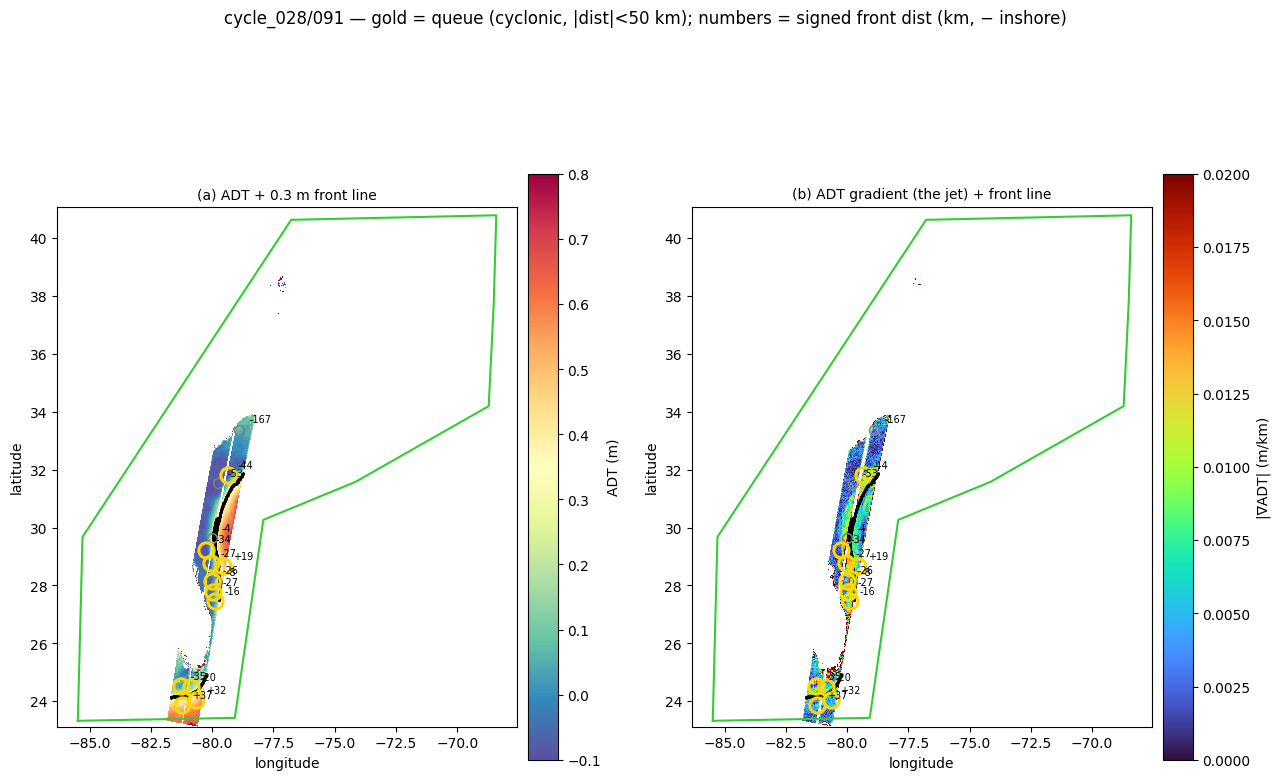

In [3]:
keep = feat[feat["kind"] == "keep"]
cand = keep[(keep.dist_front_adt_km.abs() < 50) & (keep.polarity == "cyclonic")]
cyc, pnum = cand.groupby(["cycle", "pass"]).size().idxmax()
dets = keep[(keep.cycle == cyc) & (keep["pass"] == pnum)]
print(f"example pass: {cyc}/{pnum} — {len(dets)} detections, "
      f"{len(dets.merge(cand))} queue candidates")

granule = ft.find_granule(cfg["data_root"], cyc, pnum)
nf = ft.native_fields(granule, cfg)
front = ft.front_vertices(nf["adt"], nf["lon"], nf["lat"], LEVEL, MIN_V)

def aoi_rings(geom):
    geoms = geom.geoms if geom.geom_type == "MultiPolygon" else [geom]
    return [g.exterior.xy for g in geoms]

midlat = float(np.nanmean(nf["lat"]))
fig, ax = plt.subplots(1, 2, figsize=(13, 9))
for a, fld, cmap, vmin, vmax, lbl, ttl in (
        (ax[0], nf["adt"], "Spectral_r", -0.1, 0.8, "ADT (m)",
         f"(a) ADT + {LEVEL} m front line"),
        (ax[1], nf["grad_adt"], "turbo", 0, 0.02, "|∇ADT| (m/km)",
         "(b) ADT gradient (the jet) + front line")):
    pm = a.pcolormesh(nf["lon"], nf["lat"], fld, cmap=cmap, vmin=vmin, vmax=vmax,
                      shading="nearest")
    a.plot(front[:, 0], front[:, 1], ".", color="k", ms=2, zorder=5)
    for xs, ys in aoi_rings(aoi.geom):
        a.plot(xs, ys, color="limegreen", lw=1.5, zorder=4)
    for d in dets.itertuples():
        q = (abs(d.dist_front_adt_km) < 50) and (d.polarity == "cyclonic")
        c = "gold" if q else "0.5"
        a.plot(d.lon, d.lat, "o", color=c, ms=11 if q else 7, mfc="none",
               mew=2.2 if q else 1.2, zorder=7)
        if np.isfinite(d.dist_front_adt_km):
            a.annotate(f"{d.dist_front_adt_km:+.0f}", (d.lon, d.lat),
                       textcoords="offset points", xytext=(7, 5), fontsize=7,
                       color="k", zorder=8)
    a.set_aspect(1 / np.cos(np.deg2rad(midlat)))
    a.set_xlabel("longitude"); a.set_ylabel("latitude"); a.set_title(ttl, fontsize=10)
    fig.colorbar(pm, ax=a, shrink=0.7, pad=0.02).set_label(lbl)
fig.suptitle(f"{cyc}/{pnum} — gold = queue (cyclonic, |dist|<50 km); "
             "numbers = signed front dist (km, − inshore)", y=0.99)
plt.tight_layout(); plt.show()

## Why this works: front distance by hand label (805 labels, cycles 1–7)

Frontal eddies pile up just inshore (−) of the line; open ocean lives far offshore (+);
coastal far inshore. Recomputed from the saved per-eddy distances.

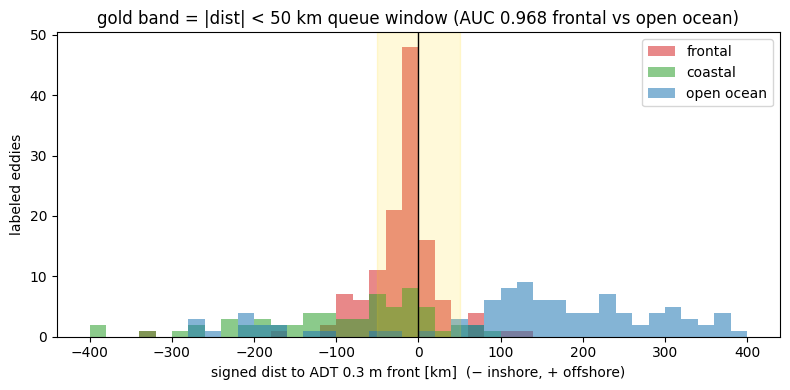

In [4]:
fd = pd.read_csv(Path(cfg["out_root"]) / "aoi5" / "features" / "front_dists_labeled.csv")
fig, a = plt.subplots(figsize=(8, 4))
bins = np.arange(-400, 401, 20)
for cls, color in (("frontal", "tab:red"), ("coastal", "tab:green"),
                   ("open ocean", "tab:blue")):
    a.hist(fd.loc[fd.label == cls, "dist_front_adt_km"], bins=bins, alpha=0.55,
           label=cls, color=color)
a.axvline(0, color="k", lw=1); a.axvspan(-50, 50, color="gold", alpha=0.15)
a.set_xlabel(f"signed dist to ADT {LEVEL} m front [km]  (− inshore, + offshore)")
a.set_ylabel("labeled eddies"); a.legend()
a.set_title("gold band = |dist| < 50 km queue window (AUC 0.968 frontal vs open ocean)")
plt.tight_layout(); plt.show()

## Label the front-sorted queue (manual approval)

Queue = **every unlabeled cyclonic detection within 50 km of the ADT front**, all 50
cycles, grouped by pass so each ~15 s pass-load yields several eddies. Expected from the
labeled sample: ~53% frontal, ~38% junk, remainder coastal/open-ocean.

Rebuild anytime (skips everything already labeled):
```
.venv/bin/python scripts/build_queue.py --size 0 --cyclonic
```
Buttons/hotkeys as in notebook 02: `1` frontal, `2` coastal, `3` open ocean, `4` reject,
`s` skip, arrows = nav. Writes the SAME resumable labels CSV
(`out/aoi5/labels/eddy_labels_aoi5.csv`). Status bar shows each eddy's signed front
distance.

In [2]:
from swot_eddy.review import CatalogLabeler

queue = sorted((Path(cfg["out_root"]) / "aoi5" / "queue").glob("queue_*.csv"))[-1]
print("labeling from:", queue.name)
CatalogLabeler(cfg, queue=queue).show()

labeling from: queue_002.csv


<IPython.core.display.Javascript object>

## Queue progress

In [ ]:
# Queue progress + remaining counts (queue = the actual task; rest gets rule/model labels).
q = pd.read_csv(queue, dtype={"cycle": str, "pass": str})
lp = Path(cfg["out_root"]) / "aoi5" / "labels" / "eddy_labels_aoi5.csv"
lab = pd.read_csv(lp, dtype={"cycle": str, "pass": str})
done = set(zip(lab.cycle, lab["pass"], lab.kind, lab.eddy))

q_left = q[[k not in done for k in zip(q.cycle, q["pass"], q.kind, q.eddy)]]
q_done = q.merge(lab, on=["cycle", "pass", "kind", "eddy"])
keep = feat[feat.kind == "keep"]
u_all = keep[[k not in done for k in zip(keep.cycle, keep["pass"], keep.kind, keep.eddy)]]

print(f"QUEUE REMAINING: {len(q_left)} / {len(q)}   (labeled this queue: {len(q_done)})")
if len(q_done):
    print("queue labels so far:", dict(q_done["label"].value_counts()))
    print(f"frontal fraction: {(q_done['label'] == 'frontal').mean():.0%} (rule predicted ~53%)")
print(f"\ntotal labels overall: {len(lab)}")
print(f"unlabeled keep, whole catalog: {len(u_all)} (NOT your task — rule/model covers these)")